In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 查看当前文件夹
print("当前文件夹：", Path.cwd())

# 读取成员三交来的文件
pred = pd.read_csv("predictions_all.csv")
cv_best = pd.read_csv("cv_best_per_model.csv")
cv_full = pd.read_csv("cv_results_full.csv")
split = pd.read_csv("split_record.csv")

print("预测数据行数：", len(pred))
print("模型与特征组合数：",
      pred[["model", "feature_set"]].drop_duplicates().shape[0])

display(pred.head())

当前文件夹： C:\Users\86133\Desktop\5001_member4
预测数据行数： 28368
模型与特征组合数： 16


,listing_id,y_true,y_pred,model,feature_set
0,5668626687,840,907.583353,linear,set1
1,5668610290,1495,908.653238,linear,set1
2,5668627023,890,910.258065,linear,set1
3,5668627099,990,912.932777,linear,set1
4,5668624367,1095,951.983571,linear,set1


In [2]:
# 建立结果文件夹
out = Path("evaluation_outputs")
out.mkdir(exist_ok=True)

# 计算预测误差
pred["residual"] = pred["y_true"] - pred["y_pred"]
pred["absolute_error"] = pred["residual"].abs()
pred["squared_error"] = pred["residual"] ** 2

# 分别计算16组模型的测试集指标
metrics = (
    pred.groupby(["feature_set", "model"], as_index=False)
    .agg(
        n=("y_true", "size"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean")
    )
)

metrics["RMSE"] = np.sqrt(metrics["MSE"])
metrics = metrics[["feature_set", "model", "n", "MAE", "RMSE"]]

# 加入成员三提供的交叉验证结果
comparison = metrics.merge(
    cv_best[["feature_set", "model", "cv_rmse", "cv_mae"]],
    on=["feature_set", "model"],
    validate="one_to_one"
).sort_values("cv_rmse").reset_index(drop=True)

# 保存完整精度，屏幕上显示两位小数
comparison.to_csv(
    out / "model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

display(comparison.round(2))
print("已保存：evaluation_outputs/model_comparison.csv")

,feature_set,model,n,MAE,RMSE,cv_rmse,cv_mae
0,set4,lasso,1773,206.13,279.15,276.18,203.36
1,set4,ridge,1773,210.45,284.73,281.13,206.90
2,set3,lasso,1773,208.89,282.76,282.73,209.49
3,set3,ridge,1773,213.60,288.95,287.41,212.54
4,set3,knn,1773,232.74,332.85,322.86,230.07
5,set4,knn,1773,248.17,351.38,334.32,241.11
6,set4,linear,1773,283.36,442.34,425.97,273.40
7,set3,linear,1773,286.13,444.94,430.08,277.91
8,set2,linear,1773,373.56,474.42,452.21,354.68
9,set2,lasso,1773,373.57,474.42,452.21,354.68


已保存：evaluation_outputs/model_comparison.csv


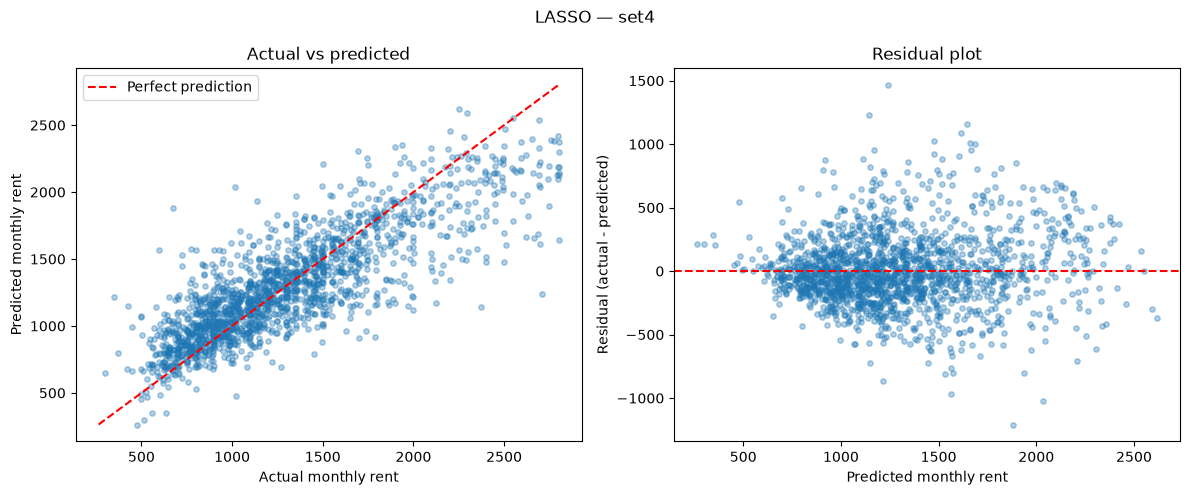

已保存：evaluation_outputs/best_model_diagnostics.png


In [3]:
# 根据交叉验证结果确定首选模型
chosen = comparison.iloc[0]

best_pred = pred[
    (pred["model"] == chosen["model"]) &
    (pred["feature_set"] == chosen["feature_set"])
].copy()

title = f'{chosen["model"].upper()} — {chosen["feature_set"]}'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 左图：真实租金与预测租金
axes[0].scatter(
    best_pred["y_true"], best_pred["y_pred"],
    alpha=0.35, s=15
)

lo = min(best_pred["y_true"].min(), best_pred["y_pred"].min())
hi = max(best_pred["y_true"].max(), best_pred["y_pred"].max())

axes[0].plot([lo, hi], [lo, hi], "r--", label="Perfect prediction")
axes[0].set(
    xlabel="Actual monthly rent",
    ylabel="Predicted monthly rent",
    title="Actual vs predicted"
)
axes[0].legend()

# 右图：残差 = 真实值 - 预测值
axes[1].scatter(
    best_pred["y_pred"], best_pred["residual"],
    alpha=0.35, s=15
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(
    xlabel="Predicted monthly rent",
    ylabel="Residual (actual - predicted)",
    title="Residual plot"
)

fig.suptitle(title)
fig.tight_layout()
fig.savefig(out / "best_model_diagnostics.png", dpi=300)
plt.show()

print("已保存：evaluation_outputs/best_model_diagnostics.png")

In [4]:
# 用训练集确定租金分组边界
train_rent = split.loc[split["split"] == "train", "y_true"]
q1, q2 = train_rent.quantile([1/3, 2/3])

print(f"低租金：≤ {q1:.2f}")
print(f"中租金：> {q1:.2f} 且 ≤ {q2:.2f}")
print(f"高租金：> {q2:.2f}")

best_pred["rent_group"] = pd.cut(
    best_pred["y_true"],
    bins=[-np.inf, q1, q2, np.inf],
    labels=["Low", "Middle", "High"]
)

group_metrics = (
    best_pred.groupby("rent_group", observed=True)
    .agg(
        n=("y_true", "size"),
        mean_actual_rent=("y_true", "mean"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean"),
        mean_residual=("residual", "mean")
    )
    .reset_index()
)

group_metrics["RMSE"] = np.sqrt(group_metrics["MSE"])
group_metrics = group_metrics[
    ["rent_group", "n", "mean_actual_rent",
     "MAE", "RMSE", "mean_residual"]
]

group_metrics.to_csv(
    out / "error_by_rent_group.csv",
    index=False,
    encoding="utf-8-sig"
)

display(group_metrics.round(2))
print("已保存：evaluation_outputs/error_by_rent_group.csv")

低租金：≤ 999.00
中租金：> 999.00 且 ≤ 1410.00
高租金：> 1410.00


,rent_group,n,mean_actual_rent,MAE,RMSE,mean_residual
0,Low,596,800.77,186.06,246.24,-157.41
1,Middle,560,1195.79,154.17,202.90,-38.20
2,High,617,1852.14,272.68,357.75,198.41


已保存：evaluation_outputs/error_by_rent_group.csv


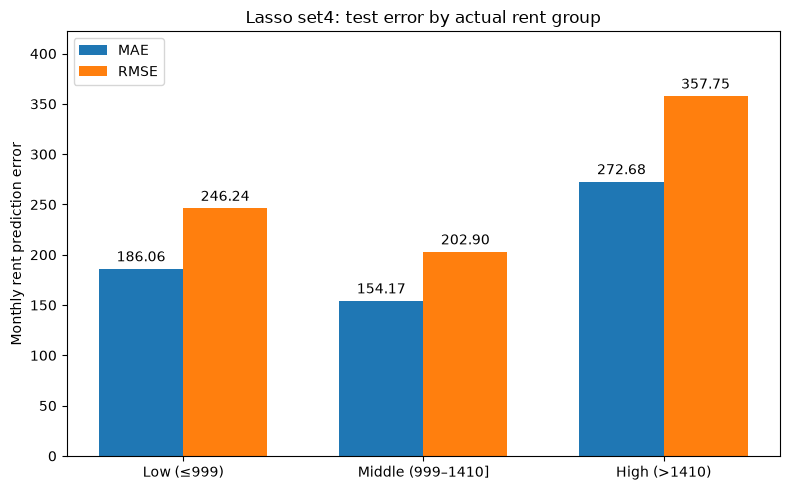

In [5]:
# 保存分组边界，方便报告说明和复现
pd.DataFrame({
    "boundary": ["training_33_percentile", "training_67_percentile"],
    "rent": [q1, q2]
}).to_csv(out / "rent_group_boundaries.csv", index=False)

# 绘制各租金组的 MAE 和 RMSE
x = np.arange(len(group_metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    x - width / 2, group_metrics["MAE"],
    width, label="MAE"
)
bars2 = ax.bar(
    x + width / 2, group_metrics["RMSE"],
    width, label="RMSE"
)

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(["Low (≤999)", "Middle (999–1410]", "High (>1410)"])
ax.set(
    ylabel="Monthly rent prediction error",
    title="Lasso set4: test error by actual rent group"
)
ax.set_ylim(0, group_metrics["RMSE"].max() * 1.18)
ax.legend()

fig.tight_layout()
fig.savefig(out / "error_by_rent_group.png", dpi=300)
plt.show()

In [6]:
# 保存首选模型的预测和残差，方便复核
best_pred.to_csv(
    out / "best_model_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

report = """Model evaluation and error analysis

All 16 model–feature combinations were evaluated on the same 1,773 test observations. The preferred model was selected using training-set cross-validation RMSE.

Lasso with set4 achieved the lowest cross-validation RMSE (276.18). Its test MAE was 206.13 and test RMSE was 279.15. Set4 includes floor area, bedrooms, bathrooms, city, state and recorded amenities. Compared with Lasso set3, adding amenities slightly reduced test RMSE from 282.76 to 279.15. However, KNN performed worse with set4 than set3, so adding features did not consistently improve prediction.

The actual-versus-predicted plot shows that predictions broadly follow actual rents, although some large errors remain. Several high-rent listings are underpredicted.

Rent groups were defined using the training-set 33rd and 67th percentiles: low (rent ≤999), middle (999 < rent ≤1410), and high (rent >1410). The test groups contained 596, 560 and 617 observations, respectively. Their MAEs were 186.06, 154.17 and 272.68, and their RMSEs were 246.24, 202.90 and 357.75. Mean residuals (actual minus predicted) were -157.41, -38.20 and 198.41. Thus, within these groups, low rents were overpredicted on average and high rents were underpredicted.

These results describe performance on one held-out split of the filtered listing data. They do not establish performance on future listings or other rental markets. Errors remain substantial for some properties, particularly in the high-rent group. Grouping by actual rent is a descriptive diagnostic and does not establish the cause of the observed error pattern.
"""

(out / "evaluation_report.txt").write_text(
    report, encoding="utf-8"
)

print("英文结果说明已保存。")
print("当前输出文件：")
for file in sorted(out.iterdir()):
    if file.is_file():
        print(file.name)

英文结果说明已保存。
当前输出文件：
best_model_diagnostics.png
best_model_predictions.csv
error_by_rent_group.csv
error_by_rent_group.png
evaluation_report.txt
model_comparison.csv
rent_group_boundaries.csv
